# Phase 4 — Explanations & Fairness

Final phase: explaining the **logistic regression** chosen in Phase 3
(cutoff **0.717**, fit on fiscal years 2014-2019, evaluated on 2020-2022),
using the exact same features/preprocessing/split as Phases 2-3
(`scripts/features.py`, `scripts/model.py`).

1. **SHAP**: logistic regression (`LinearExplainer`) vs. random forest and
   XGBoost (`TreeExplainer`, for comparison only -- neither is the final
   model) on the test set. Do all three rely on the same features, in the
   same direction?
2. **Fairness**: HBCU vs. other institutions at the fixed 0.717 cutoff, with
   bootstrap 95% CIs (the HBCU group is small -- 128 of 4046 test rows).
3. **Oakwood University case study** (EIN 63-0366652): SHAP waterfalls for
   FY2021 and FY2022, and what drove the jump in predicted risk between them.
4. **COVID-19 check**: distress rate and model performance by fiscal year,
   plus a diagnostic-only refit on 2020-2022 to see whether the relationship
   between features and distress shifted during the pandemic years.

See `NOTES.md` ("Phase 4") for the full log of problems hit and fixes.


In [1]:
import sys
sys.path.insert(0, "../scripts")

import numpy as np
import pandas as pd
import shap

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

from config import OAKWOOD_EIN
from features import (
    FEATURE_COLS,
    apply_clip,
    apply_imputer,
    build_features,
    fit_clip_bounds,
    fit_median_imputer,
)
from model import (
    LABEL_COL,
    evaluate_at_threshold,
    fit_logistic,
    fit_random_forest,
    fit_xgboost,
    predict_proba,
    time_based_split,
)
from fairness import bootstrap_group_metrics, group_summary

FINAL_THRESHOLD = 0.717

panel = pd.read_csv("../data/processed/panel.csv", dtype={"opeid": str, "ein": str})
feat = build_features(panel)
print(f"Panel: {panel.shape[0]} rows, {panel['unitid'].nunique()} institutions, "
      f"years {panel['fiscal_year'].min()}-{panel['fiscal_year'].max()}")


C:\Users\nolan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Panel: 16813 rows, 1901 institutions, years 2014-2023


## Step 0 — Same split and final-fit models as Phase 3

Train 2014-2019, test 2020-2022, winsorize/impute bounds fit on the full
training set (identical to Phase 3's Step 6). The logistic regression here
**is** the Phase 3 final model (same `fit_logistic` call, no extra
hyperparameters, cutoff 0.717). Random forest and XGBoost are refit with
their own Phase 3 best hyperparameters (`n_estimators=300, max_depth=None,
min_samples_leaf=5` / `n_estimators=100, max_depth=5, learning_rate=0.05`)
*only* so Part 1 can compare what they rely on -- they are not candidates
for production use here, that decision was already made in Phase 3.


In [2]:
labeled = feat[feat[LABEL_COL].notna()].copy()
TRAIN_YEARS = range(2014, 2020)
TEST_YEARS = range(2020, 2023)

train_df, test_df = time_based_split(labeled, TRAIN_YEARS, TEST_YEARS)

clip_bounds = fit_clip_bounds(train_df, FEATURE_COLS)
train_clipped = apply_clip(train_df, clip_bounds, FEATURE_COLS)
test_clipped = apply_clip(test_df, clip_bounds, FEATURE_COLS)

impute_values = fit_median_imputer(train_clipped, FEATURE_COLS)
train_ready = apply_imputer(train_clipped, impute_values, FEATURE_COLS)
test_ready = apply_imputer(test_clipped, impute_values, FEATURE_COLS)

logit = fit_logistic(train_ready, FEATURE_COLS)
rf = fit_random_forest(train_ready, FEATURE_COLS, n_estimators=300, max_depth=None, min_samples_leaf=5)
xgbm = fit_xgboost(train_ready, FEATURE_COLS, n_estimators=100, max_depth=5, learning_rate=0.05)

print(f"Train: {len(train_df)} rows ({train_df[LABEL_COL].mean():.1%} distressed), "
      f"Test: {len(test_df)} rows ({test_df[LABEL_COL].mean():.1%} distressed)")


Train: 8981 rows (7.3% distressed), Test: 4046 rows (5.3% distressed)


## Part 1 — SHAP: does every model rely on the same features?

Each model gets the SHAP algorithm suited to it:

- **Logistic regression**: `shap.LinearExplainer` on the *scaled* features
  (the same `StandardScaler` fit inside `fit_logistic`'s pipeline), with the
  scaled training rows as the background distribution. Its SHAP values are
  in **log-odds** units (pre-sigmoid), matching the model's own decision
  function.
- **Random forest**: `shap.TreeExplainer`, exact (tree-structure-based, no
  background sampling needed). A `RandomForestClassifier`'s leaves already
  output class probabilities, so these SHAP values are in **probability**
  units -- only the class-1 (distressed) output is kept.
- **XGBoost**: `shap.TreeExplainer`, exact. Its raw output is the log-odds
  margin (like logistic regression), so its SHAP values are in **log-odds**
  units too.

Random forest's values are therefore on a different scale from the other
two (probability vs. log-odds) -- comparing raw magnitudes across all three
isn't meaningful, but comparing **which features matter most** and **which
direction they push predictions** is, since both are scale-invariant.


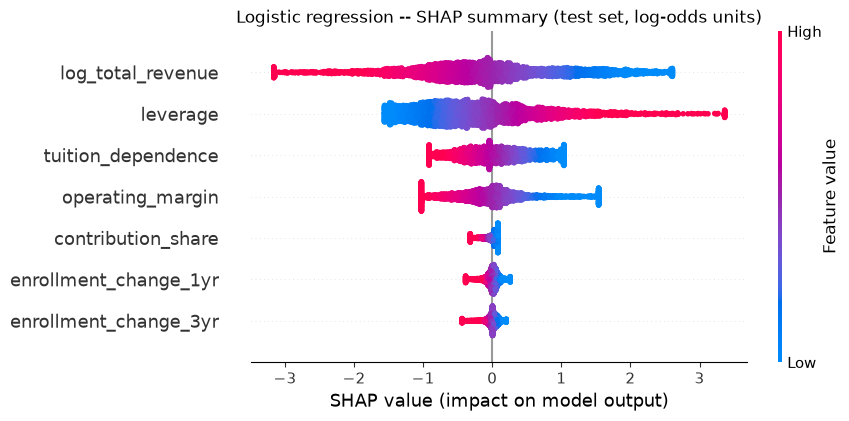

In [3]:
scaler = logit.named_steps["standardscaler"]
logit_clf = logit.named_steps["logisticregression"]

X_train_scaled = scaler.transform(train_ready[FEATURE_COLS])
X_test_scaled = scaler.transform(test_ready[FEATURE_COLS])

logit_masker = shap.maskers.Independent(X_train_scaled, max_samples=len(X_train_scaled))
logit_explainer = shap.LinearExplainer(logit_clf, logit_masker)
logit_shap = logit_explainer(X_test_scaled)
logit_shap.feature_names = FEATURE_COLS

shap.plots.beeswarm(logit_shap, show=False)
import matplotlib.pyplot as plt
from pathlib import Path

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.title("Logistic regression -- SHAP summary (test set, log-odds units)")
plt.gcf().savefig(FIG_DIR / "phase4_shap_beeswarm_logistic.png", dpi=150, bbox_inches="tight")
plt.show()


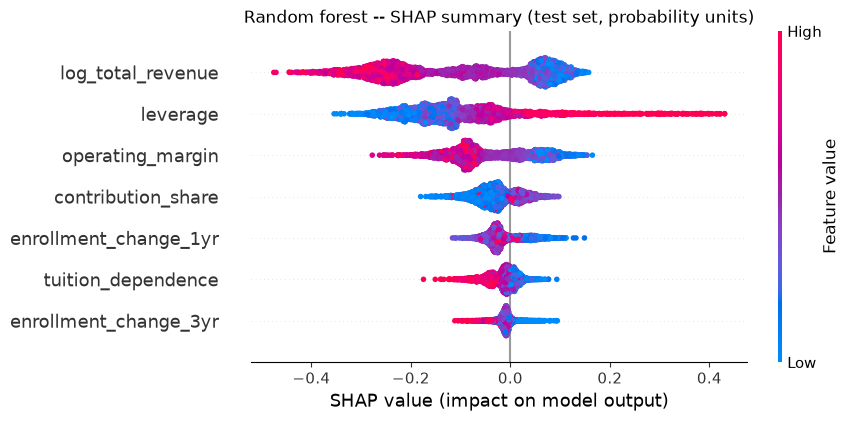

In [4]:
rf_explainer = shap.TreeExplainer(rf)
rf_shap_full = rf_explainer(test_ready[FEATURE_COLS])
rf_shap = rf_shap_full[:, :, 1]
rf_shap.feature_names = FEATURE_COLS

shap.plots.beeswarm(rf_shap, show=False)
plt.title("Random forest -- SHAP summary (test set, probability units)")
plt.gcf().savefig(FIG_DIR / "phase4_shap_beeswarm_rf.png", dpi=150, bbox_inches="tight")
plt.show()


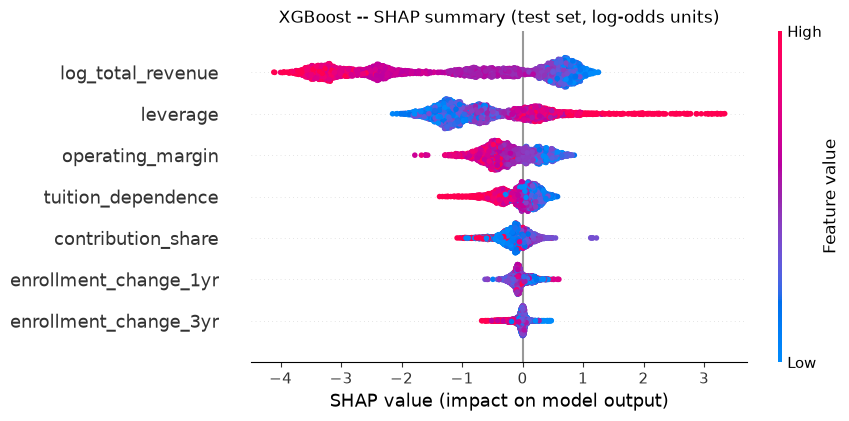

In [5]:
xgb_explainer = shap.TreeExplainer(xgbm)
xgb_shap = xgb_explainer(test_ready[FEATURE_COLS])
xgb_shap.feature_names = FEATURE_COLS

shap.plots.beeswarm(xgb_shap, show=False)
plt.title("XGBoost -- SHAP summary (test set, log-odds units)")
plt.gcf().savefig(FIG_DIR / "phase4_shap_beeswarm_xgb.png", dpi=150, bbox_inches="tight")
plt.show()


### Cross-model agreement

Ranking each model's features by **mean |SHAP|** (importance, scale-free
within a model) and separately checking each feature's **mean *signed*
SHAP among rows where that feature is above its own median** vs. below --
if a feature's SHAP values run consistently higher when the feature itself
is higher, it's pushing risk *up* as it increases; consistently lower
means it pushes risk *down* as it increases. This direction check doesn't
depend on units, so it is comparable across all three models even though
random forest's SHAP values live on a different scale than the other two.


In [6]:
def shap_direction(shap_values_obj, raw_feature_df, feature_cols):
    """For each feature: mean |SHAP| (importance) and the sign of
    corr(feature value, SHAP value) across test rows -- positive means
    higher feature values push the prediction toward distress."""
    values = shap_values_obj.values
    rows = []
    for j, col in enumerate(feature_cols):
        sv_col = values[:, j]
        raw_col = raw_feature_df[col].to_numpy()
        corr = np.corrcoef(raw_col, sv_col)[0, 1]
        rows.append({
            "feature": col,
            "mean_abs_shap": np.abs(sv_col).mean(),
            "direction": "higher -> more risk" if corr > 0 else "higher -> less risk",
        })
    return pd.DataFrame(rows).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)


logit_direction = shap_direction(logit_shap, test_ready, FEATURE_COLS)
rf_direction = shap_direction(rf_shap, test_ready, FEATURE_COLS)
xgb_direction = shap_direction(xgb_shap, test_ready, FEATURE_COLS)

direction_table = (
    logit_direction[["feature", "direction"]].rename(columns={"direction": "logistic"})
    .merge(rf_direction[["feature", "direction"]].rename(columns={"direction": "random_forest"}), on="feature")
    .merge(xgb_direction[["feature", "direction"]].rename(columns={"direction": "xgboost"}), on="feature")
)
direction_table["all_agree"] = (
    (direction_table["logistic"] == direction_table["random_forest"])
    & (direction_table["logistic"] == direction_table["xgboost"])
)
direction_table


,feature,logistic,random_forest,xgboost,all_agree
0,log_total_revenue,higher -> less risk,higher -> less risk,higher -> less risk,True
1,leverage,higher -> more risk,higher -> more risk,higher -> more risk,True
2,tuition_dependence,higher -> less risk,higher -> less risk,higher -> less risk,True
3,operating_margin,higher -> less risk,higher -> less risk,higher -> less risk,True
4,contribution_share,higher -> less risk,higher -> more risk,higher -> more risk,False
5,enrollment_change_1yr,higher -> less risk,higher -> less risk,higher -> less risk,True
6,enrollment_change_3yr,higher -> less risk,higher -> less risk,higher -> less risk,True


In [7]:
n_agree = int(direction_table["all_agree"].sum())
n_total = len(direction_table)
print(f"All three models agree on direction for {n_agree}/{n_total} features.")
if n_agree < n_total:
    print("Disagreement on:", direction_table.loc[~direction_table["all_agree"], "feature"].tolist())

importance_rank = pd.DataFrame({
    "logistic_rank": logit_direction.reset_index().set_index("feature")["index"],
    "rf_rank": rf_direction.reset_index().set_index("feature")["index"],
    "xgb_rank": xgb_direction.reset_index().set_index("feature")["index"],
}).sort_values("logistic_rank")
importance_rank


All three models agree on direction for 6/7 features.
Disagreement on: ['contribution_share']


,logistic_rank,rf_rank,xgb_rank
feature,,,
log_total_revenue,0,0,0
leverage,1,1,1
tuition_dependence,2,5,3
operating_margin,3,2,2
contribution_share,4,3,4
enrollment_change_1yr,5,4,5
enrollment_change_3yr,6,6,6


## Part 2 — Fairness: HBCU vs. other institutions

Using the IPEDS `hbcu` flag (1 = HBCU, 2 = not), compare the final
logistic model's test-set predictions **at the fixed 0.717 cutoff** across
the two groups: row counts, actual distress counts, recall, false positive
rate, and precision. The HBCU group is small (128 rows, 9 actually
distressed), so point estimates alone could be noise -- bootstrap 95% CIs
(2,000 resamples within each group) are reported alongside the raw counts.


In [8]:
logit_test_probs = predict_proba(logit, test_ready, FEATURE_COLS)
logit_test_pred = (logit_test_probs >= FINAL_THRESHOLD).astype(int)
y_test = test_ready[LABEL_COL].astype(int).to_numpy()

groups = {"HBCU": test_ready["hbcu"] == 1, "Other": test_ready["hbcu"] == 2}
assert (test_ready["hbcu"].isin([1, 2])).all(), "unexpected hbcu code outside {1, 2}"

fairness_rows = []
for name, mask in groups.items():
    mask = mask.to_numpy()
    g_true, g_pred = y_test[mask], logit_test_pred[mask]
    summary = group_summary(g_true, g_pred)
    boot = bootstrap_group_metrics(g_true, g_pred, n_boot=2000, random_state=0)
    fairness_rows.append({
        "group": name,
        "n": summary["n"],
        "n_distressed": summary["n_distressed"],
        "tp": summary["tp"], "fp": summary["fp"], "tn": summary["tn"], "fn": summary["fn"],
        "recall": summary["recall"],
        "recall_95ci": boot["recall_ci"],
        "fpr": summary["fpr"],
        "fpr_95ci": boot["fpr_ci"],
        "precision": summary["precision"],
        "precision_95ci": boot["precision_ci"],
    })

fairness_table = pd.DataFrame(fairness_rows).set_index("group")
fairness_table


,n,n_distressed,tp,fp,tn,fn,recall,recall_95ci,fpr,fpr_95ci,precision,precision_95ci
group,,,,,,,,,,,,
HBCU,128,9,4,14,105,5,0.444444,"(0.125, 0.8)",0.117647,"(0.06557377049180328, 0.18181818181818182)",0.222222,"(0.05256578947368421, 0.4401111111111105)"
Other,3918,205,107,269,3444,98,0.521951,"(0.45410566400473235, 0.5924462072636033)",0.072448,"(0.06440312584209108, 0.08090665590857384)",0.284574,"(0.23797126240164215, 0.33519607640468013)"


Reading the table: recall and FPR confidence intervals that overlap
heavily between the two groups mean the gap in point estimates could
plausibly be bootstrap noise from the HBCU group's small size, not a real
difference in model behavior -- the interpretation in the saved report
weighs this explicitly rather than treating the point estimates alone as
conclusive.


## Part 3 — Oakwood University case study (EIN 63-0366652)

Oakwood's predicted probability under the final model jumped from 0.168
(FY2021, well under the 0.717 cutoff) to 0.466 (FY2022, still under cutoff
but up sharply) in the Phase 3 results. SHAP waterfalls for both years show
which features drove that jump, using the same logistic `LinearExplainer`
as Part 1 -- with the **raw (clipped+imputed) feature values** swapped in
for display in place of the standardized ones SHAP computes on internally,
so the plot reads in the features' own units.


In [9]:
oak_feat = feat[feat["ein"] == OAKWOOD_EIN].sort_values("fiscal_year").copy()
oak_clipped = apply_clip(oak_feat, clip_bounds, FEATURE_COLS)
oak_ready = apply_imputer(oak_clipped, impute_values, FEATURE_COLS)
oak_ready = oak_ready[oak_ready["fiscal_year"].between(2020, 2023)].reset_index(drop=True)

oak_ready["predicted_prob"] = predict_proba(logit, oak_ready, FEATURE_COLS)

oak_table = oak_ready[["fiscal_year", "composite_score", LABEL_COL, "predicted_prob"] + FEATURE_COLS]
oak_table


,fiscal_year,composite_score,distressed_next_year,predicted_prob,operating_margin,leverage,tuition_dependence,contribution_share,enrollment_change_1yr,enrollment_change_3yr,log_total_revenue
0,2020,2.5,0.0,0.208099,0.008911,0.183460,0.376946,0.130607,-0.099607,-0.196961,17.882198
1,2021,3.0,0.0,0.168201,0.134648,0.188051,0.295669,0.117702,0.056769,-0.112469,17.937060
2,2022,2.2,NaN,0.466454,-0.163768,0.339100,0.323576,0.108991,0.012397,-0.036697,17.812906
3,2023,NaN,NaN,0.489710,-0.130033,0.352398,0.287638,0.138508,-0.102721,-0.040029,17.892265


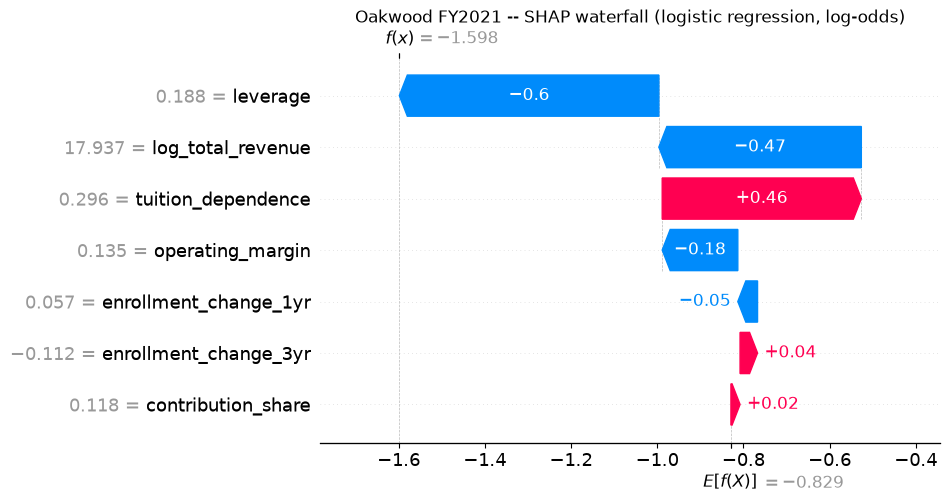

In [10]:
X_oak_scaled = scaler.transform(oak_ready[FEATURE_COLS])
oak_shap = logit_explainer(X_oak_scaled)
oak_shap.feature_names = FEATURE_COLS
oak_shap.data = oak_ready[FEATURE_COLS].to_numpy()  # display in raw units, not standardized

year_to_row = {int(y): i for i, y in enumerate(oak_ready["fiscal_year"])}

shap.plots.waterfall(oak_shap[year_to_row[2021]], show=False)
plt.title("Oakwood FY2021 -- SHAP waterfall (logistic regression, log-odds)")
plt.gcf().savefig(FIG_DIR / "phase4_oakwood_waterfall_2021.png", dpi=150, bbox_inches="tight")
plt.show()


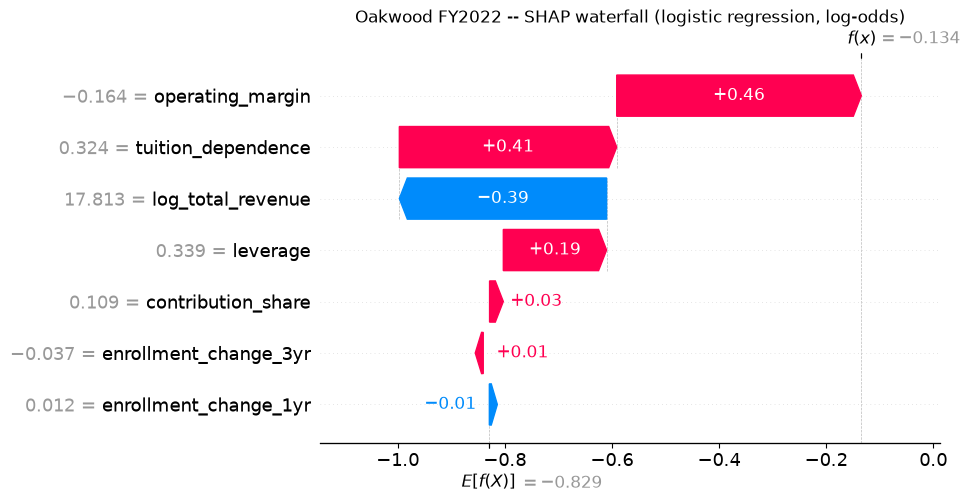

In [11]:
shap.plots.waterfall(oak_shap[year_to_row[2022]], show=False)
plt.title("Oakwood FY2022 -- SHAP waterfall (logistic regression, log-odds)")
plt.gcf().savefig(FIG_DIR / "phase4_oakwood_waterfall_2022.png", dpi=150, bbox_inches="tight")
plt.show()


In [12]:
oak_shap_2021 = oak_shap[year_to_row[2021]].values
oak_shap_2022 = oak_shap[year_to_row[2022]].values
oak_delta = pd.DataFrame({
    "feature": FEATURE_COLS,
    "value_2021": oak_ready.loc[year_to_row[2021], FEATURE_COLS].to_numpy(),
    "value_2022": oak_ready.loc[year_to_row[2022], FEATURE_COLS].to_numpy(),
    "shap_2021": oak_shap_2021,
    "shap_2022": oak_shap_2022,
})
oak_delta["shap_delta"] = oak_delta["shap_2022"] - oak_delta["shap_2021"]
oak_delta = oak_delta.sort_values("shap_delta", key=abs, ascending=False).reset_index(drop=True)
oak_delta


,feature,value_2021,value_2022,shap_2021,shap_2022,shap_delta
0,leverage,0.188051,0.339100,-0.602180,0.192839,0.795019
1,operating_margin,0.134648,-0.163768,-0.175458,0.456734,0.632192
2,log_total_revenue,17.937060,17.812906,-0.469828,-0.386997,0.082831
3,tuition_dependence,0.295669,0.323576,0.462054,0.405914,-0.056140
4,enrollment_change_1yr,0.056769,0.012397,-0.045770,-0.011357,0.034413
5,enrollment_change_3yr,-0.112469,-0.036697,0.040556,0.011799,-0.028757
6,contribution_share,0.117702,0.108991,0.021173,0.025659,0.004486


The feature(s) at the top of `shap_delta` above -- ranked by the
*change* in their own SHAP contribution from FY2021 to FY2022, not their
absolute size in either year -- are what actually drove Oakwood's jump in
predicted risk; a feature can have a large SHAP value in both years and
still contribute nothing to the *change* if it didn't move. The written
interpretation in `reports/phase4_results.txt` names these explicitly from
this table's own top rows, rather than being hardcoded.


## Part 4 — COVID-19 check

Two questions: (1) did the actual distress rate move during the pandemic
years, and (2) does the final model's performance hold up year-by-year
across the test window (2020-2022), rather than being an average that
hides a collapse in one particular year? A third, diagnostic-only step
refits the same logistic regression on the 2020-2022 rows themselves (its
own clip/impute bounds, never mixed with the official train/test
preprocessing) purely to see whether the *relationship* between features
and distress looks different during the pandemic years -- this refit is
never used for evaluation or as a candidate model, only for comparison.


In [13]:
distress_by_year = labeled.groupby("fiscal_year")[LABEL_COL].agg(["mean", "count"]).rename(
    columns={"mean": "distress_rate", "count": "n_labeled_rows"}
)
distress_by_year


,distress_rate,n_labeled_rows
fiscal_year,,
2014,0.072776,1484
2015,0.087213,1525
2016,0.071758,1519
2017,0.068692,1514
2018,0.065663,1462
2019,0.073798,1477
2020,0.043889,1481
2021,0.056407,1436
2022,0.060230,1129


In [14]:
year_metrics_rows = []
for year in TEST_YEARS:
    sub = test_ready[test_ready["fiscal_year"] == year]
    probs = predict_proba(logit, sub, FEATURE_COLS)
    m = evaluate_at_threshold(sub[LABEL_COL], probs, FINAL_THRESHOLD)
    year_metrics_rows.append({
        "fiscal_year": year, "n": m["n"], "base_rate": m["base_rate"],
        "roc_auc": m["roc_auc"], "pr_auc": m["pr_auc"], "recall": m["recall"],
    })
year_metrics = pd.DataFrame(year_metrics_rows).set_index("fiscal_year")
year_metrics


,n,base_rate,roc_auc,pr_auc,recall
fiscal_year,,,,,
2020,1481,0.043889,0.886832,0.411565,0.707692
2021,1436,0.056407,0.852717,0.312661,0.456790
2022,1129,0.060230,0.834424,0.241452,0.411765


In [15]:
covid_clip_bounds = fit_clip_bounds(test_df, FEATURE_COLS)
covid_clipped = apply_clip(test_df, covid_clip_bounds, FEATURE_COLS)
covid_impute_values = fit_median_imputer(covid_clipped, FEATURE_COLS)
covid_ready = apply_imputer(covid_clipped, covid_impute_values, FEATURE_COLS)

covid_logit = fit_logistic(covid_ready, FEATURE_COLS)

coef_compare = pd.DataFrame({
    "feature": FEATURE_COLS,
    "coef_train_2014_2019": logit_clf.coef_[0],
    "coef_covid_2020_2022": covid_logit.named_steps["logisticregression"].coef_[0],
})
coef_compare["abs_change"] = (coef_compare["coef_covid_2020_2022"] - coef_compare["coef_train_2014_2019"]).abs()
coef_compare["sign_flip"] = np.sign(coef_compare["coef_train_2014_2019"]) != np.sign(coef_compare["coef_covid_2020_2022"])
coef_compare = coef_compare.sort_values("abs_change", ascending=False).reset_index(drop=True)
coef_compare


,feature,coef_train_2014_2019,coef_covid_2020_2022,abs_change,sign_flip
0,tuition_dependence,-0.480091,-0.836115,0.356024,False
1,contribution_share,-0.084659,-0.359281,0.274621,False
2,operating_margin,-0.369195,-0.610476,0.241281,False
3,log_total_revenue,-1.130344,-0.898342,0.232002,False
4,enrollment_change_3yr,-0.061494,-0.264663,0.203168,False
5,enrollment_change_1yr,-0.078384,0.071454,0.149838,True
6,leverage,0.991330,1.114430,0.123100,False


Both coefficient sets are standardized (each refit scales its own
training rows), so magnitudes are comparable *within* this table. A feature
with a large `abs_change` here had a notably different relationship with
distress during the pandemic years than in 2014-2019 -- read alongside
`year_metrics` above, a feature whose coefficient moved a lot *and* whose
test-year performance degraded in the same years is a real candidate
explanation, not just a diagnostic curiosity.


## Save results summary

Writes `reports/phase4_results.txt` with the headline numbers and tables
from every part above.


In [16]:
summary_lines = []


def line(s=""):
    summary_lines.append(s)


line("=" * 70)
line("PHASE 4 RESULTS SUMMARY")
line("=" * 70)
line(f"Final model: logistic regression, cutoff = {FINAL_THRESHOLD}")

line("\n--- Part 1: SHAP -- cross-model feature direction agreement ---")
line(direction_table.to_string(index=False))
line(f"\nAll three models agree on direction for {n_agree}/{n_total} features.")
if n_agree < n_total:
    line("Disagreement on: " + str(direction_table.loc[~direction_table['all_agree'], 'feature'].tolist()))
line("\nImportance rank (0 = most important) by model:")
line(importance_rank.to_string())
line("\nNote: random forest's SHAP values are in probability units; logistic regression's and")
line("XGBoost's are in log-odds units -- ranks/direction are comparable across models, raw magnitudes are not.")

line("\n--- Part 2: fairness, HBCU vs. other (test set, cutoff 0.717) ---")
line(fairness_table.to_string())
line("\n(95% CIs are from 2,000 within-group bootstrap resamples; the HBCU group's wide CIs reflect")
line("its small size (128 rows, 9 actually distressed) -- see NOTES.md for the full interpretation.)")

line("\n--- Part 3: Oakwood University (EIN 63-0366652), FY2020-2023 ---")
line(oak_table.round(4).to_string(index=False))
line("\nSHAP contribution change, FY2021 -> FY2022 (sorted by |change|):")
line(oak_delta.round(4).to_string(index=False))
top_driver = oak_delta.iloc[0]
line(f"\nLargest driver of the FY2021->FY2022 jump: '{top_driver['feature']}' "
     f"(value {top_driver['value_2021']:.4f} -> {top_driver['value_2022']:.4f}, "
     f"SHAP contribution {top_driver['shap_2021']:.4f} -> {top_driver['shap_2022']:.4f}).")

line("\n--- Part 4: COVID-19 check ---")
line("\nDistress rate by fiscal year (all labeled rows, 2014-2022):")
line(distress_by_year.round(4).to_string())
line("\nFinal model performance by test fiscal year (cutoff 0.717):")
line(year_metrics.round(4).to_string())
line("\nDiagnostic-only: logistic regression coefficients, train (2014-2019) vs. a refit on the")
line("2020-2022 (COVID-period) rows themselves -- never used for evaluation, comparison only:")
line(coef_compare.round(4).to_string(index=False))

summary_text = "\n".join(summary_lines)
print(summary_text)

with open("../reports/phase4_results.txt", "w", encoding="utf-8") as f:
    f.write(summary_text + "\n")
print("\nSaved ../reports/phase4_results.txt")


PHASE 4 RESULTS SUMMARY
Final model: logistic regression, cutoff = 0.717

--- Part 1: SHAP -- cross-model feature direction agreement ---
              feature            logistic       random_forest             xgboost  all_agree
    log_total_revenue higher -> less risk higher -> less risk higher -> less risk       True
             leverage higher -> more risk higher -> more risk higher -> more risk       True
   tuition_dependence higher -> less risk higher -> less risk higher -> less risk       True
     operating_margin higher -> less risk higher -> less risk higher -> less risk       True
   contribution_share higher -> less risk higher -> more risk higher -> more risk      False
enrollment_change_1yr higher -> less risk higher -> less risk higher -> less risk       True
enrollment_change_3yr higher -> less risk higher -> less risk higher -> less risk       True

All three models agree on direction for 6/7 features.
Disagreement on: ['contribution_share']

Importance rank (0 = m